In [1]:
import math
import numpy as np
import pandas as pd

from datetime import datetime, timedelta
from pathlib import Path
from IPython.display import display, Markdown

import matplotlib.pyplot as plt
import seaborn as sns

import folium
from folium import Choropleth, Marker, CircleMarker
from folium.plugins import MarkerCluster
import geopandas as gpd

DATASETS = Path('../datasets/us_vaccine_tracker')
CENSUS_2019_DATA = DATASETS / "2019_Census_US_Population_Data_By_State_Lat_Long.csv"
US_VACCINATION_DATA = DATASETS / "us_state_vaccinations.csv"
US_STATES_SHAPES = DATASETS / "ne_110m_admin_1_states_provinces.shp"

PERCENT_DIGITS = 3

In [16]:
population = pd.read_csv(CENSUS_2019_DATA)

display(Markdown("### Census 2019 data"))
display(Markdown(f"Dataset shape: {population.shape}"))
display(Markdown("Missing data by column:"))
display(Markdown(population.isnull().sum().to_markdown(index=True)))
display(Markdown("Top five rows:"))
display(population.head())

### Census 2019 data

Dataset shape: (51, 4)

Missing data by column:

|                 |   0 |
|:----------------|----:|
| STATE           |   0 |
| POPESTIMATE2019 |   0 |
| lat             |   0 |
| long            |   0 |

Top five rows:

,STATE,POPESTIMATE2019,lat,long
0,Alabama,4903185,32.377716,-86.300568
1,Alaska,731545,58.301598,-134.420212
2,Arizona,7278717,33.448143,-112.096962
3,Arkansas,3017804,34.746613,-92.288986
4,California,39512223,38.576668,-121.493629
5,Colorado,5758736,39.739227,-104.984856
6,Connecticut,3565287,41.764046,-72.682198
7,Delaware,973764,39.157307,-75.519722
8,District of Columbia,705749,38.895110,-77.036370
9,Florida,21477737,30.438118,-84.281296


In [3]:
vaccination = pd.read_csv(US_VACCINATION_DATA)

missing_data = pd.DataFrame(vaccination.isnull().sum(), columns=['total'])
missing_data['percent'] = 100 * round(missing_data.total / vaccination.shape[0], PERCENT_DIGITS)

display(Markdown("### Vaccination data"))
display(Markdown(f"Dataset shape: {vaccination.shape}"))
display(Markdown("Missing data by column:"))
display(Markdown(missing_data.to_markdown(index=True)))
display(Markdown("Bottom five rows:"))
display(vaccination.tail())

### Vaccination data

Dataset shape: (54628, 16)

Missing data by column:

|                                     |   total |   percent |
|:------------------------------------|--------:|----------:|
| date                                |       0 |       0   |
| location                            |       0 |       0   |
| total_vaccinations                  |   22096 |      40.4 |
| total_distributed                   |   22356 |      40.9 |
| people_vaccinated                   |   22360 |      40.9 |
| people_fully_vaccinated_per_hundred |   23977 |      43.9 |
| total_vaccinations_per_hundred      |   23878 |      43.7 |
| people_fully_vaccinated             |   22440 |      41.1 |
| people_vaccinated_per_hundred       |   23902 |      43.8 |
| distributed_per_hundred             |   23898 |      43.7 |
| daily_vaccinations_raw              |   26274 |      48.1 |
| daily_vaccinations                  |      65 |       0.1 |
| daily_vaccinations_per_million      |    2912 |       5.3 |
| share_doses_used                    |   22356 |      40.9 |
| total_boosters                      |   36512 |      66.8 |
| total_boosters_per_hundred          |   37374 |      68.4 |

Bottom five rows:

,date,location,total_vaccinations,total_distributed,people_vaccinated,people_fully_vaccinated_per_hundred,total_vaccinations_per_hundred,people_fully_vaccinated,people_vaccinated_per_hundred,distributed_per_hundred,daily_vaccinations_raw,daily_vaccinations,daily_vaccinations_per_million,share_doses_used,total_boosters,total_boosters_per_hundred
54623,2023-05-06,Wyoming,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.0,133.0,NaN,NaN,NaN
54624,2023-05-07,Wyoming,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,173.0,NaN,NaN,NaN
54625,2023-05-08,Wyoming,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,123.0,213.0,NaN,NaN,NaN
54626,2023-05-09,Wyoming,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,146.0,252.0,NaN,NaN,NaN
54627,2023-05-10,Wyoming,854132.0,1281755.0,353727.0,53.15,147.58,307619.0,61.12,221.47,NaN,170.0,294.0,0.666,219773.0,37.97


In [4]:
missing_daily_vaccination = vaccination.daily_vaccinations.isnull()
overall_percent = round(missing_daily_vaccination.sum() / vaccination.shape[0], PERCENT_DIGITS)
display(Markdown(f"Missing daily vaccination records: {overall_percent}%"))

Missing daily vaccination records: 0.001%

In [30]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score


LOCATION, PPL_VACCINATED, DAILY_VACCINATIONS = "location", "people_vaccinated", "daily_vaccinations" 
STATE, POPESTIMATE2019 = "STATE", "POPESTIMATE2019"
PCNT_VACCINATED = "percent_vaccinated"

# Get the most recent date for filtering
freshDate = (datetime
             .strptime(vaccination.date.max(), "%Y-%m-%d")
             .strftime("%Y-%m-%d"))

# Vaccination data, for most recent date
vaccinationByLocation = vaccination.loc[(vaccination.date == freshDate)][[LOCATION, PPL_VACCINATED, DAILY_VACCINATIONS]]

# Vaccination and population data
vaccinationAndPopulationByLocation = (pd
                                      .merge(population, vaccinationByLocation, how='inner', left_on=STATE,right_on=LOCATION)
                                      .drop(columns=LOCATION))

# Calculate percentage vaccinated by state
vaccinationAndPopulationByLocation[PCNT_VACCINATED] = (vaccinationAndPopulationByLocation[PPL_VACCINATED] / 
                                                       vaccinationAndPopulationByLocation[POPESTIMATE2019])

# Mode of daily vaccination
scaler = MinMaxScaler()
daily_vac_mode = vaccinationAndPopulationByLocation.groupby(STATE)[DAILY_VACCINATIONS].agg(lambda x: x.mode()[0])
daily_vac_mode_scaled =scaler.fit_transform(daily_vac_mode.values.reshape(-1, 1)).flatten()

# Fit a model over data
RANDOM_STATE = 41

encoder = LabelEncoder()
vaccinationAndPopulationByLocation['STATE_ENCODED'] = encoder.fit_transform(
    vaccinationAndPopulationByLocation[STATE]
)

X = vaccinationAndPopulationByLocation.drop([STATE, PCNT_VACCINATED, DAILY_VACCINATIONS], axis=1)
y = vaccinationAndPopulationByLocation[PCNT_VACCINATED]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=RANDOM_STATE)

model = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = model.score(X_test, y_test)

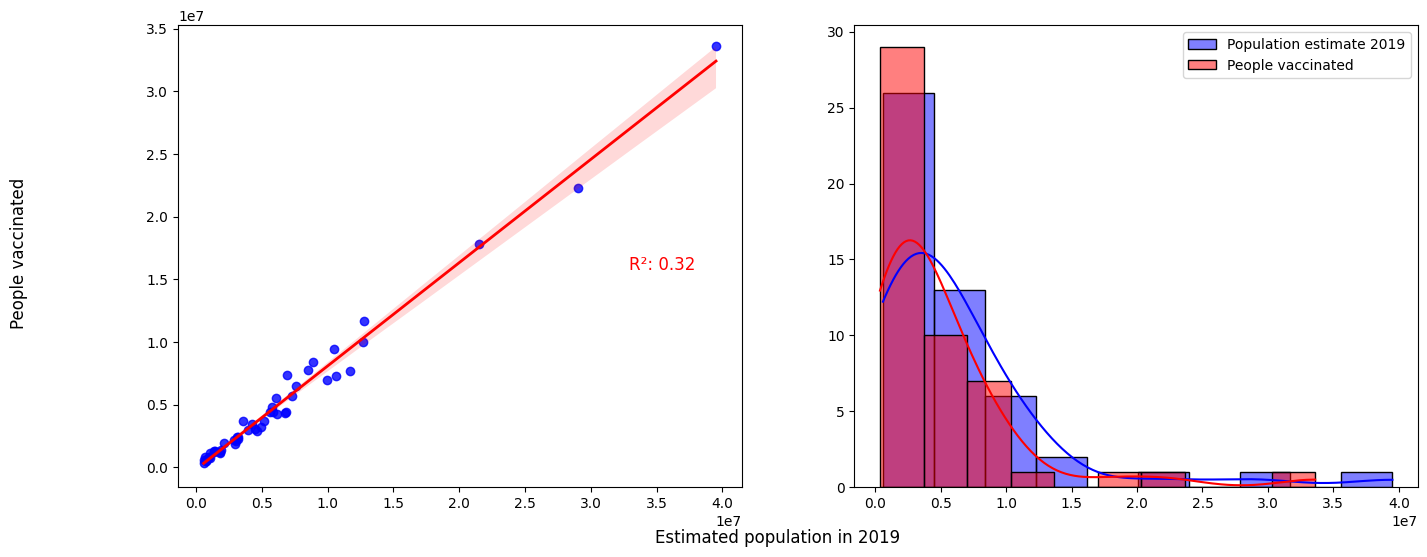

In [31]:
# Plot data
BINS = 10
COLOR1, COLOR2 = 'blue', 'red'
ANGLE = 90

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.supxlabel("Estimated population in 2019")
fig.supylabel("People vaccinated")

sns.regplot(vaccinationAndPopulationByLocation, x=POPESTIMATE2019, y=PPL_VACCINATED, ax=axes[0],
            scatter_kws={'color': COLOR1}, line_kws={'color': COLOR2, 'lw': 2})
plt.text(0.80, 0.5, f'R²: {r2:.2f}', transform=axes[0].transAxes, 
         fontsize=12, verticalalignment='top', color=COLOR2)
axes[0].set_xlabel('')
axes[0].set_ylabel('')

sns.histplot(vaccinationAndPopulationByLocation[POPESTIMATE2019], bins=BINS, kde=True, 
             color=COLOR1, ax=axes[1], label='Population estimate 2019')
sns.histplot(vaccinationAndPopulationByLocation[PPL_VACCINATED], bins=BINS, kde=True,
             color=COLOR2, ax=axes[1], label='People vaccinated')
axes[1].set_xlabel('')
axes[1].set_ylabel('')

plt.legend()
plt.show()

#bins = [0, 0.20, 0.4, 0.6, 0.8, 1]
#labels = [f"< {round(daily_vac_mode.max() * i/5, -4):.0f}" for i in range(1, len(bins))]
#categories = pd.cut(daily_vac_mode_scaled, bins=bins, labels=labels)

#plt.figure(figsize=(16, 4))
#sns.barplot(x=daily_vac_mode.index, y=daily_vac_mode_scaled, hue=categories, width=1)
#plt.title("Mode of Daily Vaccinations per State")
#plt.xlabel("State")
#plt.xticks(rotation=ANGLE)
#plt.yticks([])
#for i, value in enumerate(daily_vac_mode.values):
#    plt.text(i, daily_vac_mode_scaled[i] + 0.02, f"{value:,.0f}", ha='center', fontsize=10, rotation=ANGLE)
#plt.ylabel("Mode")
#plt.show()

In [7]:
states = gpd.read_file(US_STATES_SHAPES)

In [8]:
print(population.index.tolist())
print(len(daily_vac_mode_scaled))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50]
65


In [9]:
# Create the map
US_MAINLAND = [39.83333, -98.58552]
INIT_ZOOM = 3

v_map = folium.Map(location=US_MAINLAND, tiles='cartodbpositron', zoom_start=INIT_ZOOM)

def color_producer(val):
    if val < 0.2: return 'red'
    if val < 0.4: return 'orange'
    if val < 0.6: return 'yellow'
    if val < 0.8: return 'green'
    return 'blue' 


# Add a choropleth map to the base map
Choropleth(geo_data=states.__geo_interface__, 
           data=vaccinationAndPopulationByLocation[PCNT_VACCINATED], 
           key_on="feature.id", 
           fill_color='YlGnBu', 
           legend_name='Vaccination per State'
          ).add_to(v_map)

# Add a bubble map to the base map
for i in range(0,len(daily_vac_mode_scaled)):
    CircleMarker(
        location=[population.iloc[i]['lat'], population.iloc[i]['long']],
        radius=20,
        color=color_producer(daily_vac_mode_scaled[i])).add_to(v_map)

# Display the map
v_map

IndexError: single positional indexer is out-of-bounds